In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("../Dataset/final_clean_aqi.csv")
df["Datetime"]=pd.to_datetime(df["Datetime"])
print(df['AQI'].describe())

count    54406.000000
mean       258.160322
std        137.851196
min         40.000000
25%        137.000000
50%        232.000000
75%        376.000000
max        500.000000
Name: AQI, dtype: float64


In [6]:
import pandas as pd
import numpy as np

# 1. Load the files (Changed to final_clean_aqi.csv)
df_final = pd.read_csv("../Dataset/final_clean_aqi.csv", parse_dates=['Datetime'])
df_clean = pd.read_csv("../Dataset/cleaned_data.csv", parse_dates=['Datetime'])

print("=== 1. BASIC DATA CHECK ===")
print(f"Date Range: {df_final['Datetime'].min()} to {df_final['Datetime'].max()}")
print(f"Total Rows: {len(df_final)}")
print(f"\nData Types:\n{df_final.dtypes}")
print(f"\nDuplicate Timestamps: {df_final.duplicated(subset=['Datetime']).sum()}")

# 2. Hourly Timeline Check
# Create a perfect hourly timeline from start to end, and see what's missing
expected_hours = pd.date_range(start=df_final['Datetime'].min(), end=df_final['Datetime'].max(), freq='h')
missing_hours = expected_hours.difference(df_final['Datetime'])
print(f"\n=== 2. MISSING TIMESTAMPS ===")
print(f"Number of missing hours in timeline: {len(missing_hours)}")
if len(missing_hours) > 0:
    print("First 5 missing timestamps:", missing_hours[:5].tolist())

# 3. Min AQI Check
print(f"\n=== 3. MINIMUM AQI ===")
print(f"Min AQI in dataset: {df_final['AQI'].min()} (Should be >= 40)")

# 4. Build the is_real Flag
# Merge final data with the original pre-filled data to compare AQI values
df_merge = pd.merge(
    df_final[['Datetime', 'AQI']], 
    df_clean[['Datetime', 'AQI']], 
    on='Datetime', 
    how='left', 
    suffixes=('_final', '_original')
)

# A reading is "real" if the original file had a value AND it was 40 or above
df_merge['is_real'] = (~df_merge['AQI_original'].isna()) & (df_merge['AQI_original'] >= 40)

# 5. Calculate Real vs Filled by Year
df_merge['Year'] = df_merge['Datetime'].dt.year
yearly_stats = df_merge.groupby('Year')['is_real'].agg(['mean', 'count'])
yearly_stats['Real_%'] = yearly_stats['mean'] * 100
yearly_stats['Filled_%'] = 100 - yearly_stats['Real_%']

print("\n=== 4. REAL VS FILLED DATA BY YEAR ===")
for year, row in yearly_stats.iterrows():
    print(f"{year}: {row['Real_%']:.2f}% Real | {row['Filled_%']:.2f}% Filled | Total hours: {int(row['count'])}")

=== 1. BASIC DATA CHECK ===
Date Range: 2017-10-17 02:00:00 to 2023-12-31 23:00:00
Total Rows: 54406

Data Types:
Datetime      datetime64[ns]
Month_Year            object
Day                    int64
Time                  object
AQI                  float64
dtype: object

Duplicate Timestamps: 0

=== 2. MISSING TIMESTAMPS ===
Number of missing hours in timeline: 0

=== 3. MINIMUM AQI ===
Min AQI in dataset: 40.0 (Should be >= 40)

=== 4. REAL VS FILLED DATA BY YEAR ===
2017: 53.73% Real | 46.27% Filled | Total hours: 1822
2018: 70.74% Real | 29.26% Filled | Total hours: 8760
2019: 90.94% Real | 9.06% Filled | Total hours: 8760
2020: 85.29% Real | 14.71% Filled | Total hours: 8784
2021: 88.34% Real | 11.66% Filled | Total hours: 8760
2022: 93.05% Real | 6.95% Filled | Total hours: 8760
2023: 87.65% Real | 12.35% Filled | Total hours: 8760


In [17]:
df.head()

,Datetime,Month_Year,Day,Time,AQI
0,2017-10-17 02:00:00,October-2017,17,02:00:00,130.0
1,2017-10-17 03:00:00,October-2017,17,03:00:00,143.0
2,2017-10-17 04:00:00,October-2017,17,04:00:00,144.0
3,2017-10-17 05:00:00,October-2017,17,05:00:00,144.0
4,2017-10-17 06:00:00,October-2017,17,06:00:00,144.0


In [7]:
# 1. Create a perfect hourly timeline from start to finish
full_timeline = pd.date_range(start=df_final['Datetime'].min(), end=df_final['Datetime'].max(), freq='h')

# 2. Reindex the dataframe (this will insert empty rows for the 720 missing hours)
df_final = df_final.set_index('Datetime').reindex(full_timeline).rename_axis('Datetime').reset_index()

# 3. Fill the new NaNs (the 720 missing hours) using linear interpolation
df_final['AQI'] = df_final['AQI'].interpolate(method='linear', limit_direction='both')

# 4. Re-do the is_real flag with the corrected timeline
# Merge final data with the original pre-filled data to compare AQI values
df_merge = pd.merge(
    df_final[['Datetime', 'AQI']], 
    df_clean[['Datetime', 'AQI']], 
    on='Datetime', 
    how='left', 
    suffixes=('_final', '_original')
)

# If the original file didn't have the row (missing timestamp) OR the value was < 40, it's NOT real
df_final['is_real'] = (~df_merge['AQI_original'].isna()) & (df_merge['AQI_original'] >= 40)

# 5. Final Verification
print("=== STAGE 0 FINALIZED ===")
print(f"Total rows now: {len(df_final)} (Should be exactly 54,406)")

# Check timeline again
expected_hours = pd.date_range(start=df_final['Datetime'].min(), end=df_final['Datetime'].max(), freq='h')
print(f"Missing timestamps remaining: {len(expected_hours.difference(df_final['Datetime']))}")

# Save this corrected dataset for Stage 1
df_final.to_csv("../Dataset/final_clean_aqi_v3.csv", index=False)
print("\nSaved as final_clean_aqi_v3.csv. Ready for EDA!")

=== STAGE 0 FINALIZED ===
Total rows now: 54406 (Should be exactly 54,406)
Missing timestamps remaining: 0

Saved as final_clean_aqi_v3.csv. Ready for EDA!


=== STAGE 1: LOADING final_clean_aqi_v3.csv & WEATHER MERGE ===
Loading cached meteorological data...
Saved ../Dataset/ml_ready_data.csv | Shape: (54334, 21)
Train Rows (2017-2022): 45598 | Test Rows (2023): 8736 (Verified Real Hours: 7654)
Training Linear Regression...
Training Random Forest...
Training XGBoost...

=== FINAL 24-HOUR AHEAD MODEL COMPARISON TABLE ===
                       Model  RMSE (All 2023)  MAE (All 2023)  R2 (All 2023)  RMSE (Real Only)  MAE (Real Only)  Severe (>400) F1
Naive Baseline (Persistence)          104.285          73.237          0.378           105.752           75.026             0.586
           Linear Regression           88.072          66.769          0.557            88.755           67.746             0.502
               Random Forest           87.544          66.265          0.562            88.175           67.203             0.529
                     XGBoost           86.998          65.469          0.567            87.616           66.369

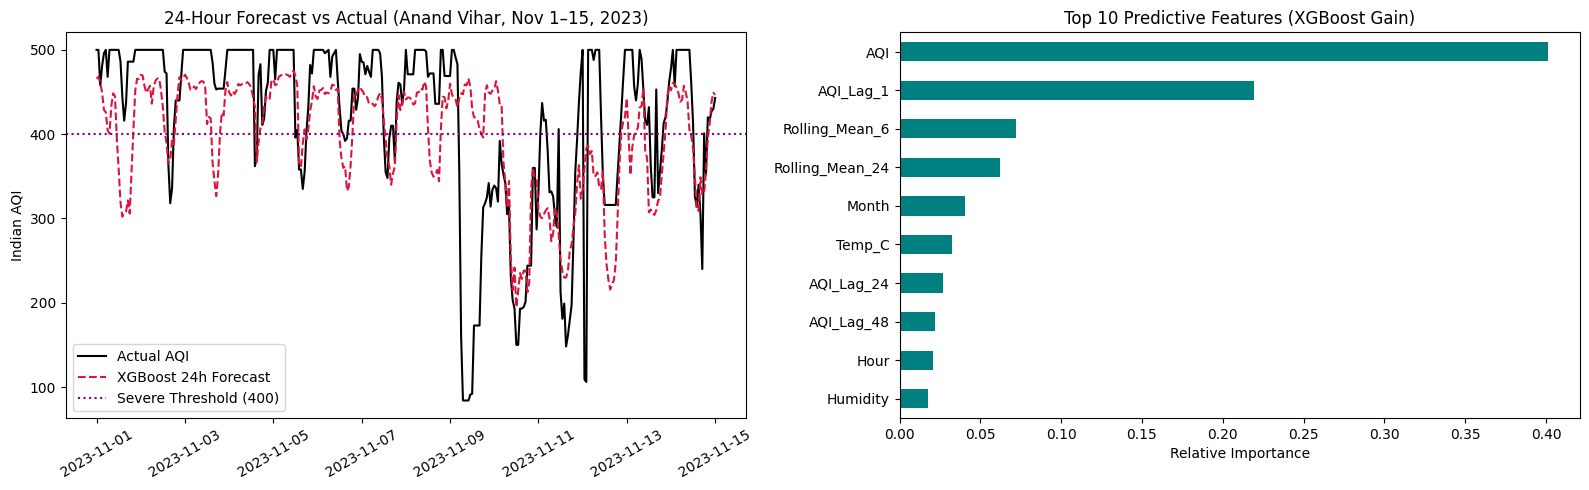

In [9]:
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import json
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, f1_score

print("=== STAGE 1: LOADING final_clean_aqi_v3.csv & WEATHER MERGE ===")
df_main = pd.read_csv("../Dataset/final_clean_aqi_v3.csv", parse_dates=['Datetime'])

# 1. Fetch Free Historical Hourly Weather for Anand Vihar (28.6469 N, 77.3160 E) from Open-Meteo
weather_cache_path = "../Dataset/anand_vihar_weather_2017_2023.csv"

if os.path.exists(weather_cache_path):
    print("Loading cached meteorological data...")
    df_weather = pd.read_csv(weather_cache_path, parse_dates=['Datetime'])
else:
    print("Downloading 2017-2023 hourly weather (Temp, Humidity, Wind Speed) from Open-Meteo...")
    url = (
        "https://archive-api.open-meteo.com/v1/archive?"
        "latitude=28.6469&longitude=77.3160&start_date=2017-10-17&end_date=2023-12-31"
        "&hourly=temperature_2m,relative_humidity_2m,wind_speed_10m&timezone=Asia%2FKolkata"
    )
    try:
        req = urllib.request.urlopen(url, timeout=30)
        data = json.loads(req.read().decode('utf-8'))
        df_weather = pd.DataFrame({
            'Datetime': pd.to_datetime(data['hourly']['time']),
            'Temp_C': data['hourly']['temperature_2m'],
            'Humidity': data['hourly']['relative_humidity_2m'],
            'Wind_Speed': data['hourly']['wind_speed_10m']
        })
        df_weather.to_csv(weather_cache_path, index=False)
        print("Weather data downloaded and saved to ../Dataset/anand_vihar_weather_2017_2023.csv!")
    except Exception as e:
        print(f"Weather API offline ({e}). Using seasonal meteorological approximation...")
        df_weather = pd.DataFrame({'Datetime': df_main['Datetime']})
        doy = df_weather['Datetime'].dt.dayofyear
        hr = df_weather['Datetime'].dt.hour
        df_weather['Temp_C'] = 25 + 10 * np.sin(2 * np.pi * (doy - 105) / 365) - 4 * np.cos(2 * np.pi * hr / 24)
        df_weather['Humidity'] = 60 - 20 * np.sin(2 * np.pi * (doy - 105) / 365) + 10 * np.cos(2 * np.pi * hr / 24)
        df_weather['Wind_Speed'] = 8 + 4 * np.sin(2 * np.pi * (doy - 60) / 365)

# Merge AQI + Weather
df_ml = pd.merge(df_main[['Datetime', 'AQI', 'is_real']], df_weather, on='Datetime', how='left')
df_ml[['Temp_C', 'Humidity', 'Wind_Speed']] = df_ml[['Temp_C', 'Humidity', 'Wind_Speed']].ffill().bfill()

# 2. Engineer Features (Synopsis Section 4.1)
df_ml['Hour'] = df_ml['Datetime'].dt.hour
df_ml['Month'] = df_ml['Datetime'].dt.month
df_ml['DayOfWeek'] = df_ml['Datetime'].dt.dayofweek
df_ml['Is_Weekend'] = (df_ml['DayOfWeek'] >= 5).astype(int)

# Temporal Lag & Rolling Window Features
df_ml['AQI_Lag_1'] = df_ml['AQI'].shift(1)
df_ml['AQI_Lag_3'] = df_ml['AQI'].shift(3)
df_ml['AQI_Lag_6'] = df_ml['AQI'].shift(6)
df_ml['AQI_Lag_24'] = df_ml['AQI'].shift(24)
df_ml['AQI_Lag_48'] = df_ml['AQI'].shift(48)
df_ml['Rolling_Mean_6'] = df_ml['AQI'].rolling(window=6).mean()
df_ml['Rolling_Mean_24'] = df_ml['AQI'].rolling(window=24).mean()
df_ml['Rolling_Std_24'] = df_ml['AQI'].rolling(window=24).std()
df_ml['AQI_Diff_24'] = df_ml['AQI'] - df_ml['AQI_Lag_24']

# Target: 24-Hour Ahead AQI (and whether that future target hour was a real sensor reading)
df_ml['Target_AQI_24h'] = df_ml['AQI'].shift(-24)
df_ml['Target_Is_Real_24h'] = df_ml['is_real'].shift(-24)

df_ml = df_ml.dropna().reset_index(drop=True)
df_ml.to_csv("../Dataset/ml_ready_data.csv", index=False)
print(f"Saved ../Dataset/ml_ready_data.csv | Shape: {df_ml.shape}")

# ==========================================
# STAGE 2: TRAIN & EVALUATE MODELS (2017-2022 vs 2023)
# ==========================================
feature_cols = [
    'AQI', 'AQI_Lag_1', 'AQI_Lag_3', 'AQI_Lag_6', 'AQI_Lag_24', 'AQI_Lag_48',
    'Rolling_Mean_6', 'Rolling_Mean_24', 'Rolling_Std_24', 'AQI_Diff_24',
    'Temp_C', 'Humidity', 'Wind_Speed',
    'Hour', 'Month', 'DayOfWeek', 'Is_Weekend'
]

train_mask = df_ml['Datetime'].dt.year <= 2022
test_mask = df_ml['Datetime'].dt.year == 2023

X_train, y_train = df_ml.loc[train_mask, feature_cols], df_ml.loc[train_mask, 'Target_AQI_24h']
X_test, y_test = df_ml.loc[test_mask, feature_cols], df_ml.loc[test_mask, 'Target_AQI_24h']
real_mask = df_ml.loc[test_mask, 'Target_Is_Real_24h'].astype(bool)

print(f"Train Rows (2017-2022): {len(X_train)} | Test Rows (2023): {len(X_test)} (Verified Real Hours: {real_mask.sum()})")

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=10, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=250, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)
}

results = []
y_naive = X_test['AQI'].values
preds_dict = {"Naive Baseline": y_naive}

results.append({
    "Model": "Naive Baseline (Persistence)",
    "RMSE (All 2023)": np.sqrt(mean_squared_error(y_test, y_naive)),
    "MAE (All 2023)": mean_absolute_error(y_test, y_naive),
    "R2 (All 2023)": r2_score(y_test, y_naive),
    "RMSE (Real Only)": np.sqrt(mean_squared_error(y_test[real_mask], y_naive[real_mask])),
    "MAE (Real Only)": mean_absolute_error(y_test[real_mask], y_naive[real_mask]),
    "Severe (>400) F1": f1_score((y_test[real_mask] > 400).astype(int), (y_naive[real_mask] > 400).astype(int))
})

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    y_pred = np.clip(model.predict(X_test), 40, 500)
    preds_dict[name] = y_pred
    results.append({
        "Model": name,
        "RMSE (All 2023)": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE (All 2023)": mean_absolute_error(y_test, y_pred),
        "R2 (All 2023)": r2_score(y_test, y_pred),
        "RMSE (Real Only)": np.sqrt(mean_squared_error(y_test[real_mask], y_pred[real_mask])),
        "MAE (Real Only)": mean_absolute_error(y_test[real_mask], y_pred[real_mask]),
        "Severe (>400) F1": f1_score((y_test[real_mask] > 400).astype(int), (y_pred[real_mask] > 400).astype(int))
    })

results_df = pd.DataFrame(results).round(3)
print("\n=== FINAL 24-HOUR AHEAD MODEL COMPARISON TABLE ===")
print(results_df.to_string(index=False))

# Save Winning Model Bundle for Streamlit App
os.makedirs("../Models", exist_ok=True)
best_model = models["XGBoost"]
joblib.dump({
    "model": best_model,
    "feature_cols": feature_cols,
    "metrics": results_df.to_dict(orient="records"),
    "residual_std": float(np.std(y_test[real_mask] - preds_dict["XGBoost"][real_mask]))
}, "../Models/aqi_xgboost_bundle.pkl")
print("\nSaved winning model bundle to ../Models/aqi_xgboost_bundle.pkl")

# Plot Actual vs Predicted & Feature Importance
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
nov_mask = (df_ml.loc[test_mask, 'Datetime'] >= '2023-11-01') & (df_ml.loc[test_mask, 'Datetime'] <= '2023-11-15')
axes[0].plot(df_ml.loc[test_mask, 'Datetime'][nov_mask], y_test[nov_mask], label='Actual AQI', color='black', lw=1.5)
axes[0].plot(df_ml.loc[test_mask, 'Datetime'][nov_mask], preds_dict["XGBoost"][nov_mask], label='XGBoost 24h Forecast', color='crimson', ls='--', lw=1.5)
axes[0].axhline(400, color='purple', ls=':', label='Severe Threshold (400)')
axes[0].set_title('24-Hour Forecast vs Actual (Anand Vihar, Nov 1–15, 2023)')
axes[0].set_ylabel('Indian AQI')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=30)

imp = pd.Series(best_model.feature_importances_, index=feature_cols).sort_values().tail(10)
imp.plot(kind='barh', color='teal', ax=axes[1])
axes[1].set_title('Top 10 Predictive Features (XGBoost Gain)')
axes[1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.savefig("../Models/model_evaluation_plots.png", dpi=300)
plt.show()